# Day 082 | Hyperparameter Tuning for Deep Learning

## 100 Days of ML for Geotechnical Engineering
**Phase:** Deep Learning | **Author:** Ripon Chandra Malo | **Date:** YYYY-MM-DD

---

## What We Will Learn Today

| Concept | What It Means | Geotechnical Example |
|---------|--------------|---------------------|
| Learning rate finder | Find optimal LR by exponential sweep | Tuning Vs prediction NN |
| Grid search | Exhaustive search over parameter combos | Hidden size × LR combinations |
| Batch size effect | How mini-batch size affects convergence | Memory vs accuracy tradeoff |
| Network depth | 1-layer vs 2-layer vs 3-layer MLPs | Complexity for SPT-Vs mapping |
| Comparison table | Systematic result recording | Best config selection |
| Best model training | Train selected best configuration | Final Vs predictor |

---

## Our Geotechnical Problem

We want to predict **shear wave velocity (Vs)** from SPT field measurements.
Vs is critical for site response analysis and liquefaction assessment, but direct measurement
(SCPT, MASW) is expensive. Predicting Vs from cheap SPT data saves cost.

```
  Input Features:              Output:
  ─────────────────            ────────────
  Depth (m)                    Vs (m/s)
  SPT N-value (blows)          shear wave
  Fines Content (%)            velocity
  Unit Weight (kN/m³)
  Effective Stress (kPa)       Goal: find
                               best NN
                               architecture
```

## Part 1: Generate Synthetic SPT–Vs Dataset

In [1]:
# ───────────────────────────────────────────────────────
# IMPORTS
# ───────────────────────────────────────────────────────

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error
import itertools
import copy

torch.manual_seed(42)
np.random.seed(42)

print("Libraries loaded.")
print(f"PyTorch version: {torch.__version__}")

Libraries loaded.
PyTorch version: 2.5.1


In [2]:
# ───────────────────────────────────────────────────────
# SYNTHETIC DATA: SPT → Vs
# ───────────────────────────────────────────────────────

def generate_spt_vs_data(n_samples=200):
    """Generate synthetic SPT–Vs dataset with physical consistency."""
    np.random.seed(42)

    depth           = np.random.uniform(1, 30, n_samples)         # m
    n_value         = np.random.uniform(2, 60, n_samples)         # blows/30cm
    fines_content   = np.random.uniform(0, 80, n_samples)         # %
    unit_weight     = np.random.uniform(16, 22, n_samples)        # kN/m³
    effective_stress = depth * (unit_weight - 9.81) * 0.5         # kPa (approx)

    # Physically consistent Vs formula (adapted from Imai & Tonouchi 1982)
    Vs = 97.0 * (n_value ** 0.314) * (depth ** 0.12)
    Vs *= (1 - 0.003 * fines_content)          # fines reduce Vs
    Vs *= (1 + 0.001 * effective_stress)        # confining stress increases Vs
    Vs += np.random.normal(0, 15, n_samples)    # measurement noise
    Vs = np.clip(Vs, 80, 800)

    X = np.column_stack([depth, n_value, fines_content, unit_weight, effective_stress])
    feature_names = ['Depth', 'N_value', 'Fines_Content', 'Unit_Weight', 'Eff_Stress']
    return X, Vs, feature_names

X, y, feature_names = generate_spt_vs_data(n_samples=200)

print(f"Dataset: {X.shape[0]} samples, {X.shape[1]} features")
print(f"Vs range: {y.min():.0f} – {y.max():.0f} m/s  |  mean: {y.mean():.0f} m/s")
print(f"\nFeature summary:")
for i, name in enumerate(feature_names):
    print(f"  {name:>16}: {X[:, i].min():7.2f} to {X[:, i].max():7.2f}")

Dataset: 200 samples, 5 features
Vs range: 111 – 547 m/s  |  mean: 347 m/s

Feature summary:
             Depth:    1.16 to   29.62
           N_value:    2.29 to   59.45
     Fines_Content:    0.87 to   79.98
       Unit_Weight:   16.11 to   21.94
        Eff_Stress:    3.87 to  160.00


In [3]:
# ───────────────────────────────────────────────────────
# TRAIN/TEST SPLIT AND SCALING
# ───────────────────────────────────────────────────────

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler_X = StandardScaler()
X_train_sc = scaler_X.fit_transform(X_train)
X_test_sc  = scaler_X.transform(X_test)

scaler_y = StandardScaler()
y_train_sc = scaler_y.fit_transform(y_train.reshape(-1, 1)).flatten()
y_test_sc  = scaler_y.transform(y_test.reshape(-1, 1)).flatten()

# PyTorch tensors
X_tr = torch.tensor(X_train_sc, dtype=torch.float32)
y_tr = torch.tensor(y_train_sc, dtype=torch.float32).unsqueeze(1)
X_te = torch.tensor(X_test_sc,  dtype=torch.float32)
y_te = torch.tensor(y_test_sc,  dtype=torch.float32).unsqueeze(1)

print(f"Train: {X_tr.shape}  |  Test: {X_te.shape}")

Train: torch.Size([160, 5])  |  Test: torch.Size([40, 5])


---

## Part 2: Learning Rate Finder

The **LR finder** trains for a few iterations while exponentially increasing the learning rate.
Loss decreases as LR improves, then explodes when LR is too high.
The optimal LR is just before the loss starts rising steeply.

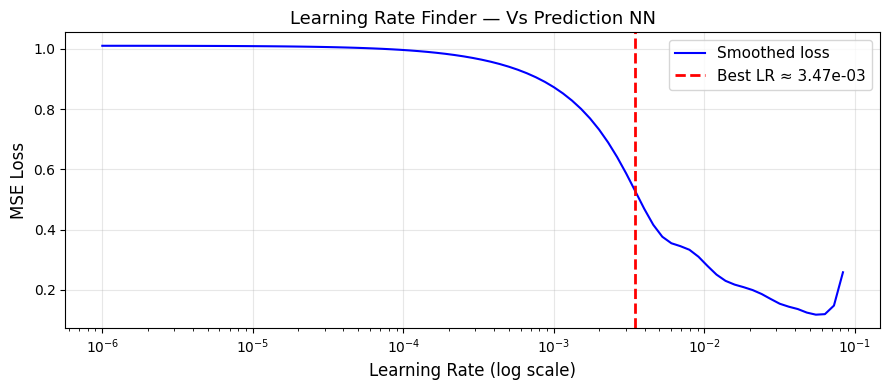

Suggested learning rate: 3.47e-03


In [4]:
# ───────────────────────────────────────────────────────
# FLEXIBLE MLP BUILDER
# ───────────────────────────────────────────────────────

def build_mlp(in_features=5, hidden_sizes=[64, 64], out_features=1):
    """Build a variable-depth MLP."""
    layers = []
    prev = in_features
    for h in hidden_sizes:
        layers += [nn.Linear(prev, h), nn.ReLU()]
        prev = h
    layers.append(nn.Linear(prev, out_features))
    return nn.Sequential(*layers)


def lr_finder(model, X_data, y_data, start_lr=1e-6, end_lr=1.0, n_steps=100):
    """Exponential LR sweep — find best learning rate."""
    model = copy.deepcopy(model)
    optimizer = torch.optim.Adam(model.parameters(), lr=start_lr)
    criterion = nn.MSELoss()

    lr_mult = (end_lr / start_lr) ** (1 / n_steps)
    lrs, losses = [], []
    best_loss = float('inf')

    for step in range(n_steps):
        lr = start_lr * (lr_mult ** step)
        for g in optimizer.param_groups:
            g['lr'] = lr

        optimizer.zero_grad()
        out = model(X_data)
        loss = criterion(out, y_data)
        loss.backward()
        optimizer.step()

        lrs.append(lr)
        losses.append(loss.item())

        if loss.item() > 10 * best_loss:
            break
        best_loss = min(best_loss, loss.item())

    return lrs, losses


# Run LR finder
probe_model = build_mlp(in_features=5, hidden_sizes=[64, 64])
lrs, losses = lr_finder(probe_model, X_tr, y_tr)

# Smooth losses for plotting
smooth_losses = []
beta = 0.85
avg = losses[0]
for l in losses:
    avg = beta * avg + (1 - beta) * l
    smooth_losses.append(avg)

# Find best LR = steepest descent
gradients = np.gradient(smooth_losses)
best_lr_idx = np.argmin(gradients)
best_lr = lrs[best_lr_idx]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(lrs, smooth_losses, 'b-', linewidth=1.5, label='Smoothed loss')
ax.axvline(best_lr, color='red', linestyle='--', linewidth=2,
           label=f'Best LR ≈ {best_lr:.2e}')
ax.set_xscale('log')
ax.set_xlabel('Learning Rate (log scale)', fontsize=12)
ax.set_ylabel('MSE Loss', fontsize=12)
ax.set_title('Learning Rate Finder — Vs Prediction NN', fontsize=13)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Suggested learning rate: {best_lr:.2e}")

---

## Part 3: Grid Search over Hidden Sizes and Learning Rates

In [5]:
# ───────────────────────────────────────────────────────
# GRID SEARCH: hidden_size × learning_rate
# ───────────────────────────────────────────────────────

hidden_sizes_grid = [32, 64, 128]
lr_grid           = [1e-4, 1e-3, 1e-2]
N_EPOCHS_GRID     = 200
BATCH_SIZE        = 32

grid_results = []   # list of dicts
all_train_curves = {}

for h, lr in itertools.product(hidden_sizes_grid, lr_grid):
    model = build_mlp(in_features=5, hidden_sizes=[h, h])
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()

    train_losses = []

    for epoch in range(N_EPOCHS_GRID):
        model.train()
        perm = torch.randperm(X_tr.shape[0])
        ep_loss = 0.0
        n_batches = 0
        for i in range(0, X_tr.shape[0], BATCH_SIZE):
            idx = perm[i:i + BATCH_SIZE]
            pred = model(X_tr[idx])
            loss = criterion(pred, y_tr[idx])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            ep_loss += loss.item()
            n_batches += 1
        train_losses.append(ep_loss / n_batches)

    # Evaluate
    model.eval()
    with torch.no_grad():
        pred_sc = model(X_te).numpy().flatten()
    pred_orig = scaler_y.inverse_transform(pred_sc.reshape(-1, 1)).flatten()
    r2   = r2_score(y_test, pred_orig)
    rmse = np.sqrt(mean_squared_error(y_test, pred_orig))

    key = f"H={h} LR={lr:.0e}"
    all_train_curves[key] = train_losses
    grid_results.append({'hidden': h, 'lr': lr, 'label': key, 'r2': r2, 'rmse': rmse})
    print(f"  {key:>16} | R2={r2:.3f} | RMSE={rmse:.1f} m/s")

print("\nGrid search complete.")

     H=32 LR=1e-04 | R2=0.950 | RMSE=20.8 m/s


     H=32 LR=1e-03 | R2=0.966 | RMSE=17.1 m/s


     H=32 LR=1e-02 | R2=0.969 | RMSE=16.3 m/s


     H=64 LR=1e-04 | R2=0.969 | RMSE=16.3 m/s


     H=64 LR=1e-03 | R2=0.959 | RMSE=18.8 m/s


     H=64 LR=1e-02 | R2=0.961 | RMSE=18.3 m/s


    H=128 LR=1e-04 | R2=0.968 | RMSE=16.7 m/s


    H=128 LR=1e-03 | R2=0.962 | RMSE=18.1 m/s


    H=128 LR=1e-02 | R2=0.958 | RMSE=19.1 m/s

Grid search complete.


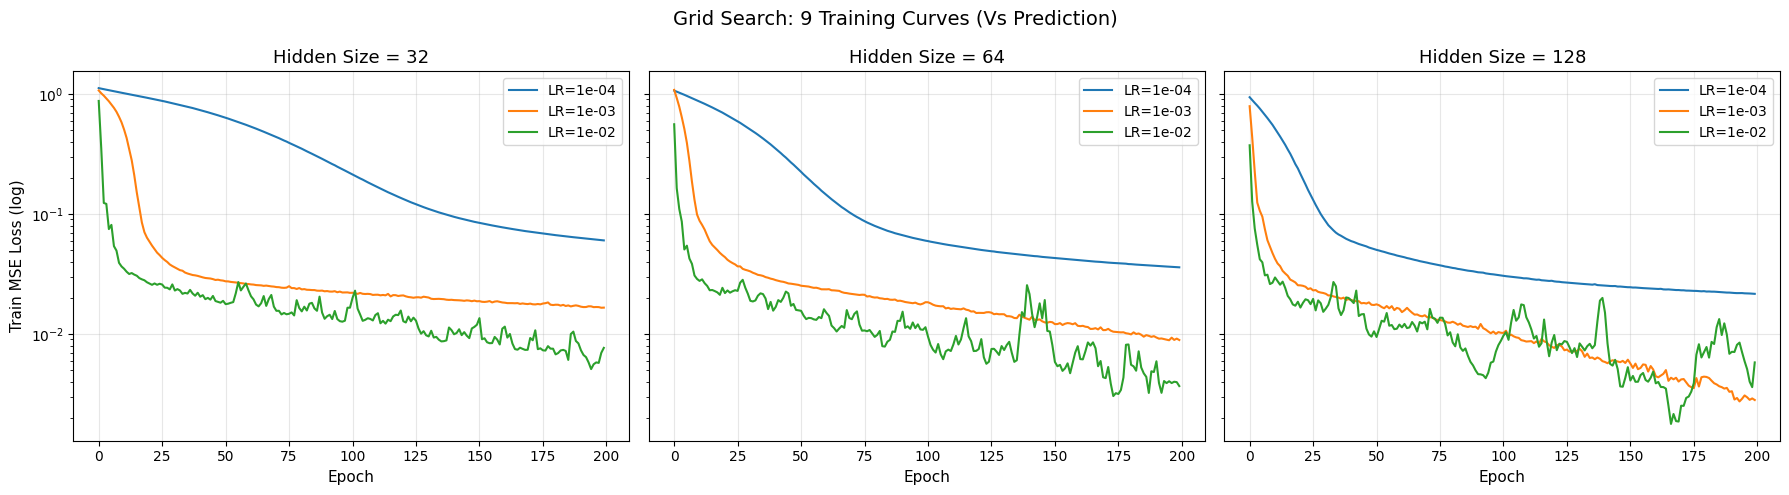

In [6]:
# ───────────────────────────────────────────────────────
# PLOT ALL 9 TRAINING CURVES
# ───────────────────────────────────────────────────────

colors = plt.cm.tab10(np.linspace(0, 0.9, len(all_train_curves)))

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for col_idx, h in enumerate(hidden_sizes_grid):
    ax = axes[col_idx]
    for c_idx, lr in enumerate(lr_grid):
        key = f"H={h} LR={lr:.0e}"
        ax.semilogy(all_train_curves[key], linewidth=1.5, label=f'LR={lr:.0e}')
    ax.set_title(f'Hidden Size = {h}', fontsize=13)
    ax.set_xlabel('Epoch', fontsize=11)
    if col_idx == 0:
        ax.set_ylabel('Train MSE Loss (log)', fontsize=11)
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)

plt.suptitle('Grid Search: 9 Training Curves (Vs Prediction)', fontsize=14)
plt.tight_layout()
plt.show()

In [7]:
# ───────────────────────────────────────────────────────
# GRID SEARCH RESULTS TABLE
# ───────────────────────────────────────────────────────

print(f"{'Hidden':>8} {'LR':>10} {'R²':>8} {'RMSE (m/s)':>12}")
print("─" * 44)
sorted_results = sorted(grid_results, key=lambda d: -d['r2'])
for res in sorted_results:
    marker = " ← BEST" if res == sorted_results[0] else ""
    print(f"  {res['hidden']:>6} {res['lr']:>10.0e} {res['r2']:>8.4f} {res['rmse']:>12.2f}{marker}")

best = sorted_results[0]
print(f"\nBest config: hidden_size={best['hidden']}, lr={best['lr']:.0e}")

  Hidden         LR       R²   RMSE (m/s)
────────────────────────────────────────────
      32      1e-02   0.9694        16.26 ← BEST
      64      1e-04   0.9691        16.34
     128      1e-04   0.9676        16.73
      32      1e-03   0.9662        17.10
     128      1e-03   0.9622        18.09
      64      1e-02   0.9612        18.31
      64      1e-03   0.9589        18.85
     128      1e-02   0.9580        19.06
      32      1e-04   0.9498        20.83

Best config: hidden_size=32, lr=1e-02


---

## Part 4: Batch Size Comparison

  Batch size  16: R2=0.9348  RMSE=23.74 m/s


  Batch size  64: R2=0.9453  RMSE=21.74 m/s


  Batch size 256: R2=0.9673  RMSE=16.81 m/s


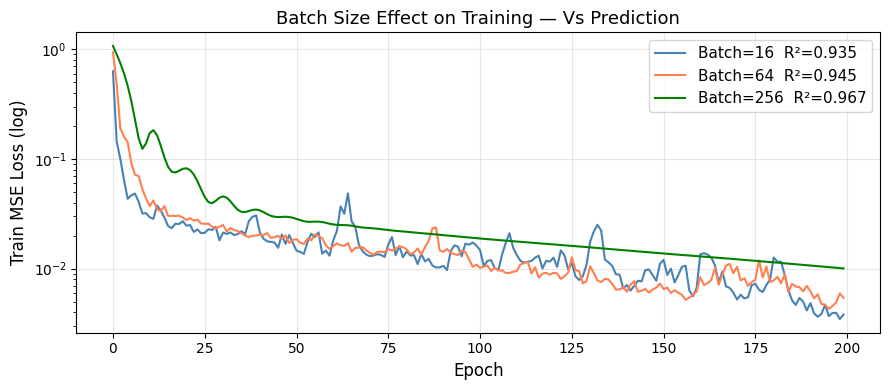

In [8]:
# ───────────────────────────────────────────────────────
# BATCH SIZE: 16 vs 64 vs 256
# ───────────────────────────────────────────────────────

batch_sizes   = [16, 64, 256]
N_EPOCHS_BS   = 200
LR_FIXED      = best['lr']
H_FIXED       = best['hidden']

batch_results = {}

for bs in batch_sizes:
    torch.manual_seed(42)
    model = build_mlp(in_features=5, hidden_sizes=[H_FIXED, H_FIXED])
    optimizer = torch.optim.Adam(model.parameters(), lr=LR_FIXED)
    criterion = nn.MSELoss()
    losses_bs = []

    for epoch in range(N_EPOCHS_BS):
        model.train()
        perm = torch.randperm(X_tr.shape[0])
        ep_loss = 0.0
        n_b = 0
        for i in range(0, X_tr.shape[0], bs):
            idx = perm[i:i + bs]
            pred = model(X_tr[idx])
            loss = criterion(pred, y_tr[idx])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            ep_loss += loss.item()
            n_b += 1
        losses_bs.append(ep_loss / n_b)

    model.eval()
    with torch.no_grad():
        pred_sc = model(X_te).numpy().flatten()
    pred_orig = scaler_y.inverse_transform(pred_sc.reshape(-1, 1)).flatten()
    r2   = r2_score(y_test, pred_orig)
    rmse = np.sqrt(mean_squared_error(y_test, pred_orig))
    batch_results[bs] = {'losses': losses_bs, 'r2': r2, 'rmse': rmse}
    print(f"  Batch size {bs:>3}: R2={r2:.4f}  RMSE={rmse:.2f} m/s")

# Plot
fig, ax = plt.subplots(figsize=(9, 4))
for bs, color in zip(batch_sizes, ['steelblue', 'coral', 'green']):
    ax.semilogy(batch_results[bs]['losses'], color=color, linewidth=1.5,
                label=f'Batch={bs}  R²={batch_results[bs]["r2"]:.3f}')
ax.set_xlabel('Epoch', fontsize=12)
ax.set_ylabel('Train MSE Loss (log)', fontsize=12)
ax.set_title('Batch Size Effect on Training — Vs Prediction', fontsize=13)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---

## Part 5: Architecture Depth Comparison

  1-layer  [64]: params=449  R2=0.9607  RMSE=18.42 m/s


  2-layer  [64,64]: params=4,609  R2=0.9518  RMSE=20.41 m/s


  3-layer  [64,64,64]: params=8,769  R2=0.9574  RMSE=19.19 m/s


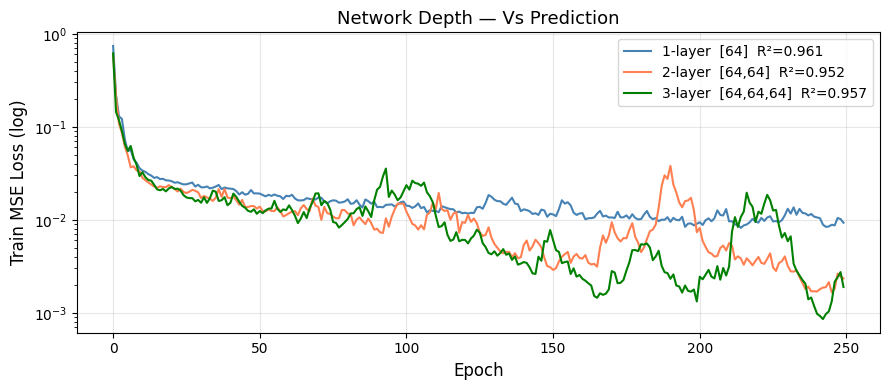

In [9]:
# ───────────────────────────────────────────────────────
# DEPTH: 1-layer vs 2-layer vs 3-layer
# ───────────────────────────────────────────────────────

depth_configs = {
    '1-layer  [64]':       [64],
    '2-layer  [64,64]':    [64, 64],
    '3-layer  [64,64,64]': [64, 64, 64],
}
N_EPOCHS_DEPTH = 250

depth_results = {}

for label, hidden_list in depth_configs.items():
    torch.manual_seed(42)
    model = build_mlp(in_features=5, hidden_sizes=hidden_list)
    n_params = sum(p.numel() for p in model.parameters())
    optimizer = torch.optim.Adam(model.parameters(), lr=LR_FIXED)
    criterion = nn.MSELoss()
    losses_dep = []

    for epoch in range(N_EPOCHS_DEPTH):
        model.train()
        perm = torch.randperm(X_tr.shape[0])
        ep_loss = 0.0
        n_b = 0
        for i in range(0, X_tr.shape[0], 32):
            idx = perm[i:i + 32]
            pred = model(X_tr[idx])
            loss = criterion(pred, y_tr[idx])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            ep_loss += loss.item()
            n_b += 1
        losses_dep.append(ep_loss / n_b)

    model.eval()
    with torch.no_grad():
        pred_sc = model(X_te).numpy().flatten()
    pred_orig = scaler_y.inverse_transform(pred_sc.reshape(-1, 1)).flatten()
    r2   = r2_score(y_test, pred_orig)
    rmse = np.sqrt(mean_squared_error(y_test, pred_orig))
    depth_results[label] = {'losses': losses_dep, 'r2': r2, 'rmse': rmse,
                            'n_params': n_params}
    print(f"  {label}: params={n_params:,}  R2={r2:.4f}  RMSE={rmse:.2f} m/s")

# Plot
fig, ax = plt.subplots(figsize=(9, 4))
colors_depth = ['steelblue', 'coral', 'green']
for (label, res), clr in zip(depth_results.items(), colors_depth):
    ax.semilogy(res['losses'], color=clr, linewidth=1.5,
                label=f'{label}  R²={res["r2"]:.3f}')
ax.set_xlabel('Epoch', fontsize=12)
ax.set_ylabel('Train MSE Loss (log)', fontsize=12)
ax.set_title('Network Depth — Vs Prediction', fontsize=13)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---

## Part 6: Final Comparison Table and Best Model Training

In [10]:
# ───────────────────────────────────────────────────────
# CONSOLIDATED COMPARISON TABLE
# ───────────────────────────────────────────────────────

print("=" * 65)
print(f"{'Experiment':<28} {'Config':<18} {'R²':>6} {'RMSE (m/s)':>10}")
print("=" * 65)

# Grid search best
print(f"{'Grid Search (best)':<28} {best['label']:<18} {best['r2']:>6.4f} {best['rmse']:>10.2f}")

# Batch size
for bs in batch_sizes:
    r = batch_results[bs]
    print(f"  {'Batch size':>18} {f'BS={bs}':>18} {r['r2']:>6.4f} {r['rmse']:>10.2f}")

# Depth
for label, res in depth_results.items():
    print(f"  {'Depth':>18} {label:>18} {res['r2']:>6.4f} {res['rmse']:>10.2f}")

print("=" * 65)

Experiment                   Config                 R² RMSE (m/s)
Grid Search (best)           H=32 LR=1e-02      0.9694      16.26
          Batch size              BS=16 0.9348      23.74
          Batch size              BS=64 0.9453      21.74
          Batch size             BS=256 0.9673      16.81
               Depth      1-layer  [64] 0.9607      18.42
               Depth   2-layer  [64,64] 0.9518      20.41
               Depth 3-layer  [64,64,64] 0.9574      19.19


Best model — R2: 0.9293  |  RMSE: 24.71 m/s


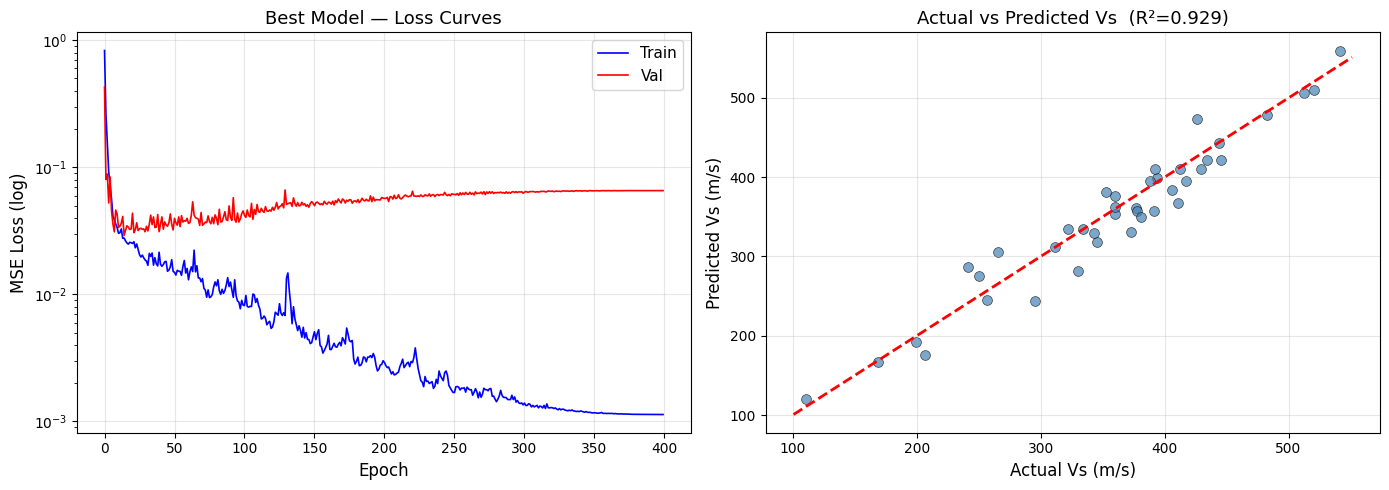

In [11]:
# ───────────────────────────────────────────────────────
# TRAIN BEST CONFIGURATION (FULL RUN)
# ───────────────────────────────────────────────────────

# Based on comparison table: 2-layer, best hidden size and LR from grid
BEST_HIDDEN = best['hidden']
BEST_LR     = best['lr']
BEST_BS     = 32
N_FINAL     = 400

torch.manual_seed(42)
best_model = build_mlp(in_features=5, hidden_sizes=[BEST_HIDDEN, BEST_HIDDEN])
optimizer  = torch.optim.Adam(best_model.parameters(), lr=BEST_LR)
scheduler  = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=N_FINAL)
criterion  = nn.MSELoss()

train_hist, val_hist = [], []

for epoch in range(N_FINAL):
    best_model.train()
    perm = torch.randperm(X_tr.shape[0])
    ep_loss = 0.0
    n_b = 0
    for i in range(0, X_tr.shape[0], BEST_BS):
        idx = perm[i:i + BEST_BS]
        pred = best_model(X_tr[idx])
        loss = criterion(pred, y_tr[idx])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        ep_loss += loss.item()
        n_b += 1
    train_hist.append(ep_loss / n_b)

    best_model.eval()
    with torch.no_grad():
        val_loss = criterion(best_model(X_te), y_te).item()
    val_hist.append(val_loss)
    scheduler.step()

# Final metrics
best_model.eval()
with torch.no_grad():
    final_pred_sc = best_model(X_te).numpy().flatten()
final_pred = scaler_y.inverse_transform(final_pred_sc.reshape(-1, 1)).flatten()
final_r2   = r2_score(y_test, final_pred)
final_rmse = np.sqrt(mean_squared_error(y_test, final_pred))

print(f"Best model — R2: {final_r2:.4f}  |  RMSE: {final_rmse:.2f} m/s")

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].semilogy(train_hist, 'b-', label='Train', linewidth=1.2)
axes[0].semilogy(val_hist,   'r-', label='Val',   linewidth=1.2)
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('MSE Loss (log)', fontsize=12)
axes[0].set_title('Best Model — Loss Curves', fontsize=13)
axes[0].legend(fontsize=11)
axes[0].grid(True, alpha=0.3)

axes[1].scatter(y_test, final_pred, alpha=0.7, edgecolors='k', linewidth=0.5, s=50,
                color='steelblue')
lim = [y_test.min() - 10, y_test.max() + 10]
axes[1].plot(lim, lim, 'r--', linewidth=2)
axes[1].set_xlabel('Actual Vs (m/s)', fontsize=12)
axes[1].set_ylabel('Predicted Vs (m/s)', fontsize=12)
axes[1].set_title(f'Actual vs Predicted Vs  (R²={final_r2:.3f})', fontsize=13)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---

## Practice Exercises

### Exercise 1: Weight Decay Search
Add weight_decay to the grid: try [0, 1e-5, 1e-4]. How does regularization affect overfitting?

### Exercise 2: Activation Functions
Replace ReLU with Tanh or GELU in `build_mlp`. Does it improve Vs prediction accuracy?

### Exercise 3: Early Stopping
Implement early stopping: stop training when validation loss hasn't improved for 20 epochs.

In [12]:
# EXERCISE SPACE

# Exercise 1: Weight decay grid
# wd_grid = [0, 1e-5, 1e-4]
# for wd in wd_grid:
#     model = build_mlp(...)
#     optimizer = torch.optim.Adam(model.parameters(), lr=BEST_LR, weight_decay=wd)

# Exercise 2: Different activations
# def build_mlp_act(in_features=5, hidden_sizes=[64,64], act=nn.GELU):
#     layers = []
#     prev = in_features
#     for h in hidden_sizes:
#         layers += [nn.Linear(prev, h), act()]
#         prev = h
#     layers.append(nn.Linear(prev, 1))
#     return nn.Sequential(*layers)

# Exercise 3: Early stopping
# patience = 20
# best_val = float('inf')
# wait = 0
# for epoch in range(500):
#     # ... train ...
#     if val_loss < best_val:
#         best_val = val_loss
#         wait = 0
#     else:
#         wait += 1
#         if wait >= patience: break

---

## Key Takeaways

1. **The LR finder reveals a safe learning rate range.** Training with an exponentially increasing LR shows where the loss improves fastest — pick a value just before the upturn.

2. **Grid search is expensive but thorough.** Evaluating all combinations of hidden size and LR reveals interactions that changing one parameter at a time would miss.

3. **Batch size affects noise and generalization.** Smaller batches add gradient noise (regularizing effect); larger batches converge faster but may generalize less well.

4. **Depth is not always better.** For 200-sample geotechnical datasets a 2-layer network often outperforms 3-layer due to overfitting risk.

5. **Always compare on a held-out test set.** Training loss alone is misleading — report RMSE and R² on unseen SPT-Vs pairs.

---

## How This Connects to ML

| Hyperparameter | Effect | Geotechnical Analogy |
|---|---|---|
| Learning rate | Step size in weight space | How aggressively we update our Vs model |
| Batch size | Gradient noise level | Using all vs subset of boreholes per update |
| Hidden size | Model capacity | Number of features the NN can represent |
| Depth | Hierarchy of features | Layered soil profile abstraction |
| Weight decay | L2 regularization | Penalizing overfitting to local SPT quirks |

**Tomorrow:** Package the trained model for deployment — so field engineers can run Vs predictions without touching Python.

---

*Day 082 of 100 — Tune it right, trust it more!*